In [34]:
import pandas as pd
import numpy as np

In [35]:
df = pd.read_excel('online_retail_II.xlsx')

In [36]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [37]:
df.dtypes

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object

In [38]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['Quantity'] = df['Quantity'].astype(float).round(3)
df['Revenue'] = (df['Quantity'] * df['Price']).round(3)
df.dtypes

Invoice                object
StockCode              object
Description            object
Quantity              float64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
Revenue               float64
dtype: object

In [39]:
print(df.duplicated().sum())
df.drop_duplicates(inplace=True)

6865


In [40]:
print(df.isna().sum())
df.dropna(inplace=True)

Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107833
Country             0
Revenue             0
dtype: int64


## Recency

In [41]:
df['InvoiceDate'].sort_values(ascending=False).head(3)

525460   2010-12-09 20:01:00
525411   2010-12-09 20:01:00
525426   2010-12-09 20:01:00
Name: InvoiceDate, dtype: datetime64[us]

In [42]:
date = '2010-12-09 20:01:00'
date = pd.to_datetime(date) + pd.Timedelta(days=1)

recency = df.groupby(['Customer ID']).agg({'InvoiceDate': lambda x: (date - x.max()).days})
recency.head()

,InvoiceDate
Customer ID,
12346.0,67
12347.0,3
12348.0,74
12349.0,43
12351.0,11


## Frequency

In [43]:
freq = df.drop_duplicates(subset='InvoiceDate').groupby(['Customer ID'])['Invoice'].count()
freq.head()

Customer ID
12346.0    12
12347.0     1
12348.0     1
12349.0     4
12351.0     1
Name: Invoice, dtype: int64

## Monetary

In [44]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12.0,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12.0,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12.0,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48.0,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24.0,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


In [45]:
monetary =df.groupby(['Customer ID'])['Revenue'].sum().round(2)
monetary.head()

Customer ID
12346.0     -51.74
12347.0    1323.32
12348.0     222.16
12349.0    2646.99
12351.0     300.93
Name: Revenue, dtype: float64

In [46]:
negative_customers = monetary[monetary < 0]
negative_customers.sort_values().head(10)

Customer ID
17399.0   -25111.09
12918.0   -10953.50
15849.0    -5876.34
15760.0    -5795.87
16981.0    -4620.86
16151.0    -4217.59
14063.0    -3767.20
18023.0    -3248.86
17013.0    -3224.76
15202.0    -2570.18
Name: Revenue, dtype: float64

## RFM

In [47]:
rfm = pd.concat([recency, freq, monetary], axis=1)
rfm.rename(columns={'InvoiceDate': 'recency',
                    'Invoice': 'frequency',
                    'Revenue': 'monetary'}, inplace=True)
rfm.head()

,recency,frequency,monetary
Customer ID,,,
12346.0,67,12.0,-51.74
12347.0,3,1.0,1323.32
12348.0,74,1.0,222.16
12349.0,43,4.0,2646.99
12351.0,11,1.0,300.93


In [48]:
rfm.dropna(inplace=True)

In [49]:
from sklearn.preprocessing import StandardScaler

x = ['recency', 'frequency', 'monetary']
scalar = StandardScaler()
scaled = scalar.fit_transform(rfm[x])

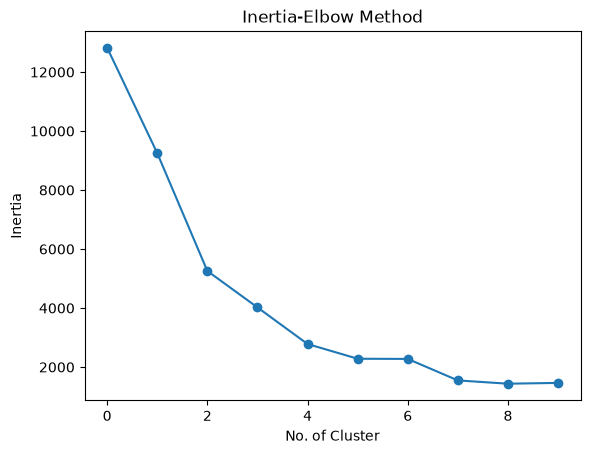

In [50]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

intertia = []
for i in np.arange(1, 11):
    kmeans = KMeans(n_clusters=i)
    kmeans.fit(scaled)
    intertia.append(kmeans.inertia_)

plt.plot(intertia, marker='o')
plt.title('Inertia-Elbow Method')
plt.xlabel('No. of Cluster')
plt.ylabel('Inertia')
plt.show()

In [51]:
intertia

[12825.0,
 9249.525578915875,
 5256.412864287078,
 4021.9017133937105,
 2780.413946727603,
 2282.041400487156,
 2275.548410942786,
 1546.8277772376007,
 1435.8386473195171,
 1462.39770757573]

In [52]:
kmeans = KMeans(n_clusters=3)
kmeans.fit(scaled)
rfm['Cluster Label'] = (kmeans.labels_ + 1)
rfm.head(10)

,recency,frequency,monetary,Cluster Label
Customer ID,,,,
12346.0,67,12.0,-51.74,1
12347.0,3,1.0,1323.32,1
12348.0,74,1.0,222.16,1
12349.0,43,4.0,2646.99,1
12351.0,11,1.0,300.93,1
12352.0,11,2.0,343.80,1
12353.0,44,1.0,317.76,1
12355.0,203,1.0,488.21,2
12356.0,16,3.0,3560.30,1


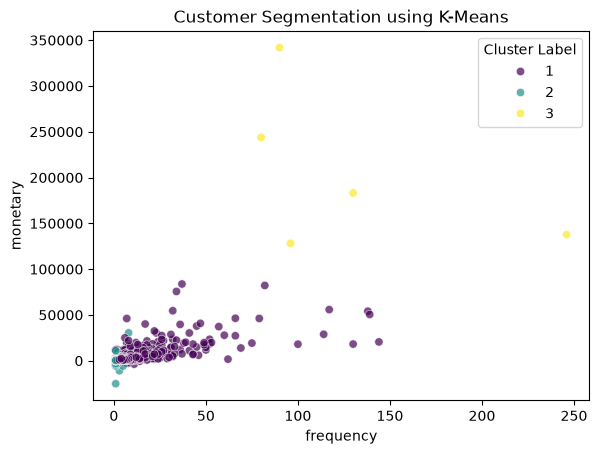

In [53]:
import seaborn as sns

sns.scatterplot(data=rfm, x='frequency', y='monetary', hue='Cluster Label', palette='viridis', alpha=0.7)
plt.title('Customer Segmentation using K-Means')
plt.show()

In [54]:
rfm.groupby(['Cluster Label']).agg({'frequency': 'mean',
                                    'recency': 'mean',
                                    'monetary': 'mean'})

,frequency,recency,monetary
Cluster Label,,,
1,5.95439,40.757989,2115.706230
2,1.86533,239.679083,416.345215
3,128.40000,5.600000,206935.302000


In [55]:
def func_condition(row):
    if row['Cluster Label'] == 1:
        return 'Average Customer'
    elif row['Cluster Label'] == 3:
        return 'Whale'
    else:
        return 'Lapsed Customer'

In [56]:
rfm['Customer Condition'] = rfm.apply(func_condition, axis=1)
rfm.head()

,recency,frequency,monetary,Cluster Label,Customer Condition
Customer ID,,,,,
12346.0,67,12.0,-51.74,1,Average Customer
12347.0,3,1.0,1323.32,1,Average Customer
12348.0,74,1.0,222.16,1,Average Customer
12349.0,43,4.0,2646.99,1,Average Customer
12351.0,11,1.0,300.93,1,Average Customer


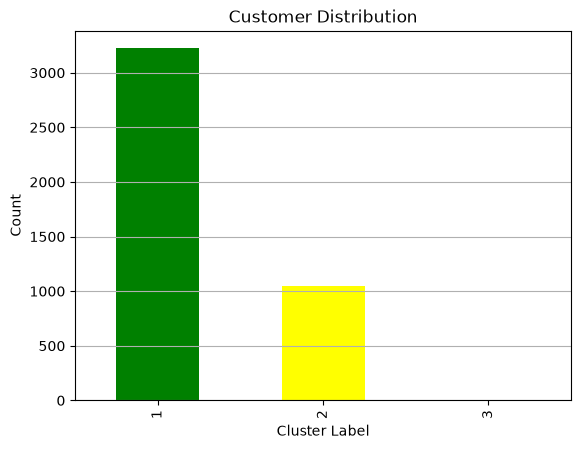

In [57]:
cluster_counts = rfm['Cluster Label'].value_counts()
cluster_counts.plot(kind='bar',color=['Green', 'Yellow', 'Orange'])
plt.title('Customer Distribution')
plt.ylabel('Count')
plt.grid(axis='y')
plt.show()

In [58]:
cluster_counts

Cluster Label
1    3223
2    1047
3       5
Name: count, dtype: int64

## Recommendations
1. Average Customers(cluster 1) contribute quite significantly to the market but they have quite higher recency than whale,this could improved by anaysing what customers buy regularly and making stock always available.
2. Lapsed Customers(cluster 2) have poor recency, frequency and monetary. Could be improved by providing extra discount to them for their relapsing in future to maintain, the momentum, profit from these customers.
3. Whales customers are very low in count. improving the quality of products and services should be the priority to maintain loyalty and trust.